# モデルの確信度が当てになるか調べる (較正、ECE)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpcookbook/blob/main/notebooks/16_evaluation/calibration_ece.ipynb)

NLP クックブック 16-16 ／ 評価指標と統計的検定

モデルが「確率 90%」と言った予測は、本当に 90% 当たっているのか。確信度の信頼性を評価し、補正したい。

In [1]:
import numpy as np
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.naive_bayes import MultinomialNB

cats = ["rec.sport.baseball", "rec.sport.hockey", "sci.space", "sci.med", "comp.graphics"]
data = fetch_20newsgroups(subset="all", categories=cats, remove=("headers", "footers", "quotes"))
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, test_size=0.4, stratify=data.target, random_state=0)
vec = TfidfVectorizer(stop_words="english", min_df=2)
Xtr, Xte = vec.fit_transform(X_train), vec.transform(X_test)

def ece(probs, labels, n_bins=10):
    """Expected Calibration Error: 確信度で区間に分け、|正解率 − 平均確信度| を事例数で重み付けして平均する"""
    conf, pred = probs.max(axis=1), probs.argmax(axis=1)
    bins = np.linspace(0, 1, n_bins + 1)
    total = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            total += m.mean() * abs((pred[m] == labels[m]).mean() - conf[m].mean())
    return total

models = {"ナイーブベイズ": MultinomialNB(alpha=0.01), "SVM + 較正 (Platt)": CalibratedClassifierCV(LinearSVC(), method="sigmoid", cv=5)}
probs = {}
for name, model in models.items():
    probs[name] = model.fit(Xtr, y_train).predict_proba(Xte)
    print(f"{name:20} 正解率 {(probs[name].argmax(1) == y_test).mean():.3f}  平均確信度 {probs[name].max(1).mean():.3f}  ECE {ece(probs[name], y_test):.3f}")

ナイーブベイズ              正解率 0.891  平均確信度 0.893  ECE 0.015
SVM + 較正 (Platt)     正解率 0.883  平均確信度 0.813  ECE 0.085


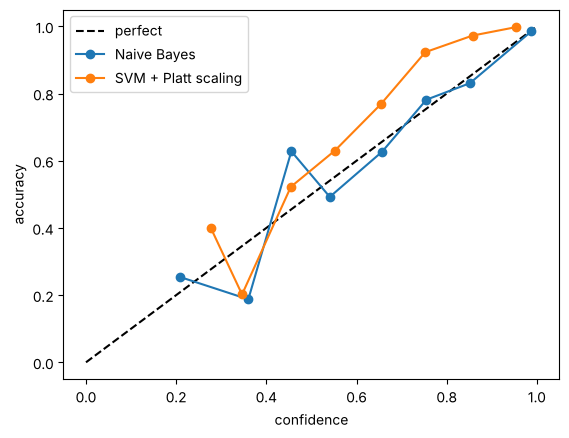

In [2]:
import matplotlib.pyplot as plt

plt.plot([0, 1], [0, 1], "k--", label="perfect")
for (name, p), label in zip(probs.items(), ["Naive Bayes", "SVM + Platt scaling"]):
    conf, correct = p.max(axis=1), p.argmax(axis=1) == y_test
    bins = np.linspace(0.2, 1, 9)
    idx = np.digitize(conf, bins)
    xs = [conf[idx == i].mean() for i in range(1, len(bins)) if (idx == i).any()]
    ys = [correct[idx == i].mean() for i in range(1, len(bins)) if (idx == i).any()]
    plt.plot(xs, ys, "o-", label=label)
plt.xlabel("confidence"); plt.ylabel("accuracy"); plt.legend(); plt.show()

- 対角線より下は自信過剰 (確信度のほうが正解率より高い)、上は自信不足。この例では、較正した SVM のほうが自信不足気味で ECE が大きい。較正の良し悪しはモデルとデータの組み合わせ次第なので、思い込みで決めずに測る。
- ニューラルモデルの較正には、検証データでソフトマックスの温度を 1 つだけ調整する temperature scaling が簡単で効果的。
- 正解率が同じでも、較正の良し悪しは違いうる。確信度でしきい値を設けて人手に回すような運用では、較正が重要になる。